**Studi kasus ini mengadaptasi poin-poin materi dari pengenalan analisis data, metodologi, hingga tingkatan analisis menggunakan bahasa pemrograman Python sebagai alternatif dari KNIME.**

Skenario Bisnis:
Sebuah platform e-commerce menyadari bahwa biaya untuk mendapatkan pelanggan baru 5x lebih mahal daripada mempertahankan pelanggan lama. Manajemen ingin mengetahui profil pelanggan yang berpotensi berhenti berlangganan belanja agar tim marketing dapat memberikan promo retensi yang tepat sasaran.

Data sebagai Aset: Kita tidak hanya melihat total penjualan, tetapi mengolah rekam jejak pelanggan untuk pengambilan keputusan promo.

In [9]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# 1. PERSIAPAN DATA (Membuat dataset & membersihkannya)
np.random.seed(42)
df = pd.DataFrame({
    'ID_Pelanggan': range(1, 101),
    'Total_Belanja': np.random.randint(100000, 5000000, 100),
    'Jumlah_Kunjungan': np.random.randint(1, 50, 100),
    'Komplain': np.random.choice(['Ya', 'Tidak'], 100, p=[0.2, 0.8]),
    'Umur_Akun_Bulan': np.random.randint(1, 60, 100),
    'Churn': np.random.choice([0, 1], 100, p=[0.7, 0.3])
})

df['Komplain_Num'] = df['Komplain'].map({'Ya': 1, 'Tidak': 0})

# 2. PEMODELAN PREDIKTIF (Mendefinisikan X_test dan y_pred)
X = df[['Total_Belanja', 'Jumlah_Kunjungan', 'Komplain_Num', 'Umur_Akun_Bulan']]
y = df['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# 3. ANALISIS PRESKRIPTIF (Logika Tindakan Bisnis)
df_hasil = X_test.copy()
df_hasil['Prediksi_Churn'] = y_pred

def rekomendasi_tindakan(row):
    if row['Prediksi_Churn'] == 1:
        if row['Komplain_Num'] == 1:
            return "Kirim Email Permintaan Maaf + Voucher Diskon 30%"
        elif row['Jumlah_Kunjungan'] < 10:
            return "Kirim Kampanye 'We Miss You' + Voucher Gratis Ongkir"
        else:
            return "Hubungi via Telepon/WhatsApp untuk Feedback"
    else:
        if row['Total_Belanja'] > 2000000:
            return "Masukkan ke Program VIP / Loyalty Premium"
        else:
            return "Kirim Katalog Produk/Newsletter Reguler"

df_hasil['Rekomendasi_Tindakan'] = df_hasil.apply(rekomendasi_tindakan, axis=1)

pd.set_option('display.max_colwidth', None)
print("Tabel Rekomendasi Tindakan Marketing:\n")
print(df_hasil[['Total_Belanja', 'Komplain_Num', 'Prediksi_Churn', 'Rekomendasi_Tindakan']].head(10))

Tabel Rekomendasi Tindakan Marketing:

    Total_Belanja  Komplain_Num  Prediksi_Churn  \
83         148984             0               0   
53        2657489             1               1   
70        2979190             0               0   
45        3497723             0               0   
44        2845683             0               0   
39        3485357             0               0   
22        4821339             0               0   
80        2713740             0               0   
10        1866891             0               0   
0         1792743             1               0   

                                Rekomendasi_Tindakan  
83           Kirim Katalog Produk/Newsletter Reguler  
53  Kirim Email Permintaan Maaf + Voucher Diskon 30%  
70         Masukkan ke Program VIP / Loyalty Premium  
45         Masukkan ke Program VIP / Loyalty Premium  
44         Masukkan ke Program VIP / Loyalty Premium  
39         Masukkan ke Program VIP / Loyalty Premium  
22         Mas

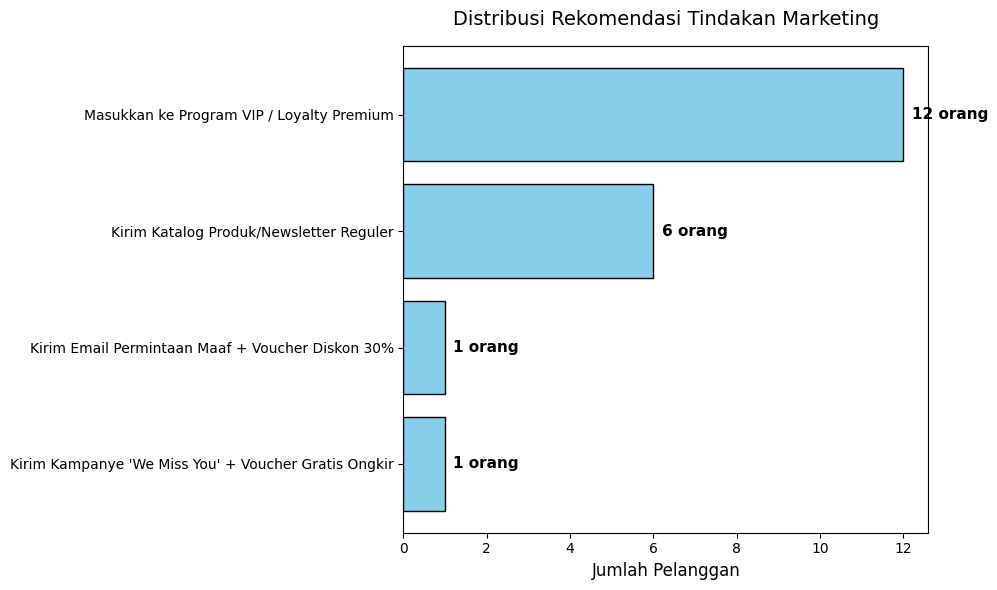

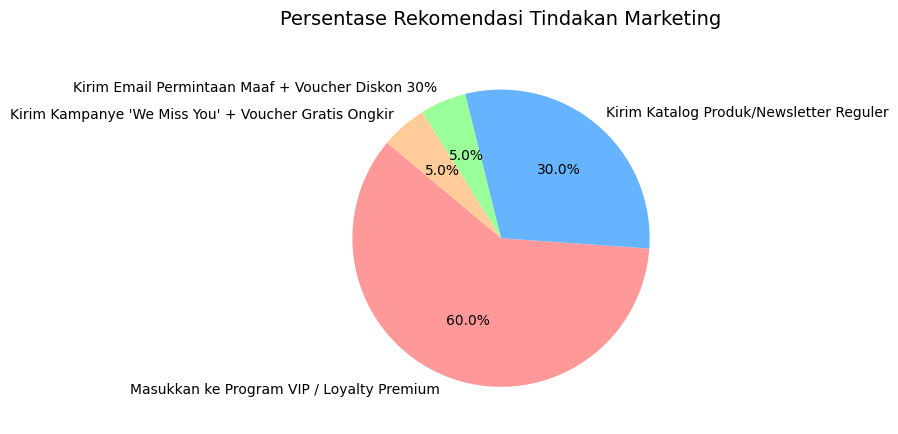

In [10]:
import matplotlib.pyplot as plt

# Menghitung jumlah pelanggan untuk setiap kategori rekomendasi
rekomendasi_counts = df_hasil['Rekomendasi_Tindakan'].value_counts()

# ==========================================
# OPSI 1: HORIZONTAL BAR CHART (Direkomendasikan)
# ==========================================
plt.figure(figsize=(10, 6))
bars = plt.barh(rekomendasi_counts.index, rekomendasi_counts.values, color='skyblue', edgecolor='black')

# Menambahkan label angka persis di sebelah kanan tiap bar
for bar in bars:
    plt.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
             f'{int(bar.get_width())} orang',
             va='center', ha='left', fontsize=11, fontweight='bold')

plt.title('Distribusi Rekomendasi Tindakan Marketing', fontsize=14, pad=15)
plt.xlabel('Jumlah Pelanggan', fontsize=12)
plt.gca().invert_yaxis() # Membalik urutan agar yang terbanyak berada di paling atas
plt.tight_layout()
plt.show()

# ==========================================
# OPSI 2: PIE CHART
# ==========================================
plt.figure(figsize=(8, 8))
# Menggunakan autopct untuk menampilkan persentase
plt.pie(rekomendasi_counts, labels=rekomendasi_counts.index, autopct='%1.1f%%',
        startangle=140, colors=['#ff9999','#66b3ff','#99ff99','#ffcc99', '#c2c2f0'])

plt.title('Persentase Rekomendasi Tindakan Marketing', fontsize=14, pad=20)
plt.tight_layout()
plt.show()

Praktik studi kasus Prediksi Retensi Pelanggan ini secara langsung membuktikan teori fundamental analisis data yang telah dibahas:

Transformasi Data Menjadi Aset: Data mentah seperti riwayat transaksi, kunjungan, dan komplain tidak dibiarkan sebagai tabel pasif, melainkan diolah untuk mencegah kerugian bisnis (kehilangan pelanggan) dan mengoptimalkan anggaran promosi agar tidak salah sasaran.

Integrasi Ketiga Level Analisis:

1. Deskriptif: Terjawab melalui peringkasan data dan visualisasi awal.
2. Prediktif: Dieksekusi oleh model Machine Learning Decision Tree untuk memproyeksikan status pelanggan di masa depan.
3. Preskriptif: Diwujudkan melalui logika rekomendasi yang secara otomatis memilah tindakan promosi apa yang paling relevan untuk masing-masing profil pelanggan.

Peran Kritis Manusia di Balik AI: Kecerdasan buatan hanya bertugas memberikan probabilitas analitis. Nilai bisnis yang sesungguhnya baru tercipta berkat logika if-else dan pemahaman konteks bisnis yang kamu rancang. Kemampuan menerjemahkan hasil prediksi algoritma menjadi strategi campaign yang empatik adalah skill fundamental manusia yang tidak tergantikan oleh AI.